In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')


## **Partie 1:**

Text(0.5, 1.0, 'Random Classification Data with 2 classes')

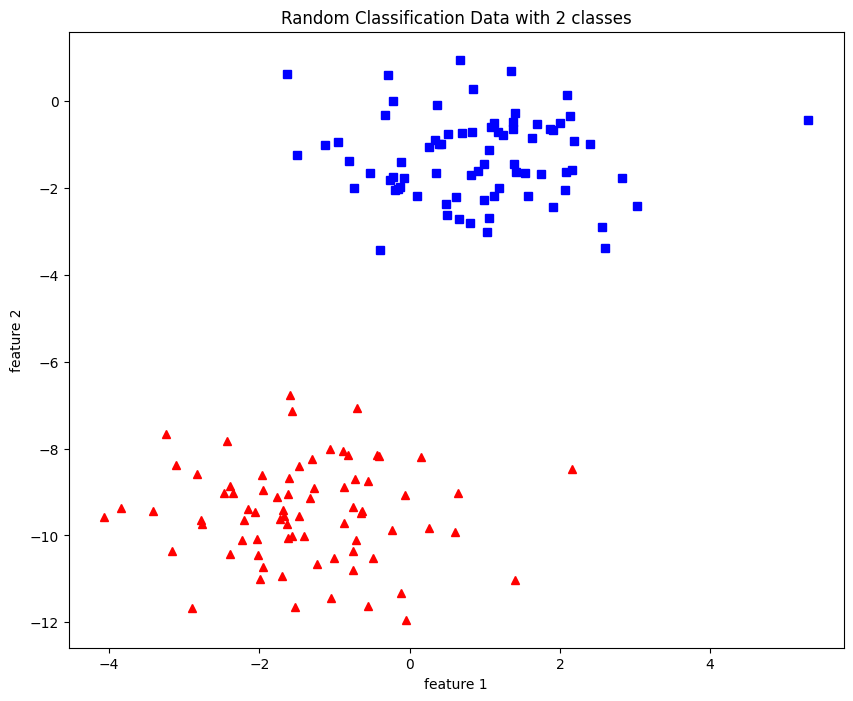

In [8]:
X, y = datasets.make_blobs (n_samples=150, n_features=2,
centers=2, cluster_std=1.05,

random_state=2)

#Plotting
fig = plt.figure(figsize=(10,8))
plt.plot(X[:, 0][y == 0], X[:, 1][y == 0], 'r^')
plt.plot(X[:, 0][y == 1], X[:, 1][y == 1], 'bs')
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title('Random Classification Data with 2 classes')

In [9]:
def acti_func(z):
    """
    Fonction d'activation de Heaviside (échelon)

    Arguments:
        z: scalaire, vecteur ou matrice - entrée du neurone (w·x + b)

    Retourne:
        1 si z >= 0, 0 sinon

    """
    return 1 if z>0 else 0

In [12]:
def perceptron(X, y, lr, epochs):
    """
    Arguments:
        X: matrice de taille (m, n) - données d'entraînement
        y: vecteur de taille (m,) - labels {0, 1}
        lr: float - learning rate (taux d'apprentissage)
        epochs: int - nombre maximal d'itérations

    Retourne:
        w: vecteur de taille (n+1,) - poids (dernier élément = biais)
        n_miss_list: nombre d’erreurs par époque
        error_list: taux d’erreur par époque
    """
    m, n = X.shape
    w = np.zeros((n+1,1))
    n_miss_list = []
    error_list=[]
    accuracy=[]
    for epoch in range(epochs):
      n_miss = 0
      for idx, x_i in enumerate(X):
        x_i = np.insert(x_i, 0, 1).reshape(-1,1)
        y_hat = acti_func(np.dot(x_i.T, w))
        if (np.squeeze(y_hat) - y[idx]) != 0:
            w-=lr*(np.squeeze(y_hat) - y[idx])*x_i
            n_miss+=1
      n_miss_list.append(n_miss)
      error_list.append(1-(m-n_miss)/m)
    return w, n_miss_list,error_list

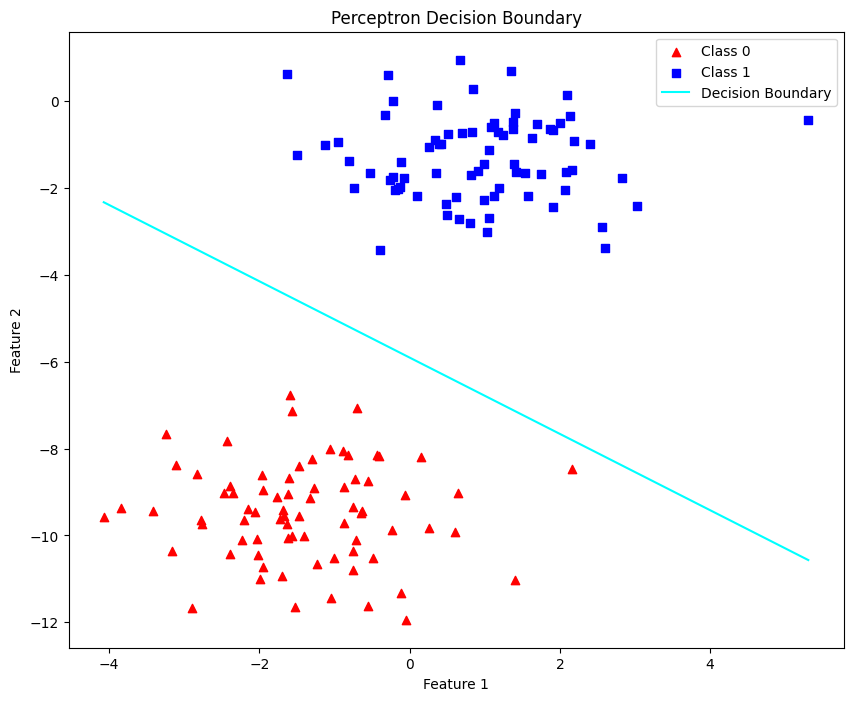

In [18]:
def plot_decision_boundary(X,y, w):
    """
Arguments:
        X: matrice de taille (m, 2) - données d'entrée avec 2 caractéristiques
        w: vecteur de taille (3,) - [biais, w1, w2] pour perceptron_01
  """
    # Assuming X has shape (m, 2) for two-dimensional features
    plt.figure(figsize=(10, 8))

    # Scatter plot for class 0 (assuming binary classification)
    plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='red', marker='^', label='Class 0')

    # Scatter plot for class 1
    plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='blue', marker='s', label='Class 1')

    m = -w[1] / w[2]
    c = -w[0] / w[2]

    x1 = [min(X[:, 0]), max(X[:, 0])]
    x2 = m * x1 + c
    plt.plot(x1, x2, color='cyan' , label='Decision Boundary')

    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title('Perceptron Decision Boundary')
    plt.legend()
    plt.show()

w, _,_ = perceptron(X, y, lr=0.01, epochs=3)
plot_decision_boundary(X,y, w)

## **Partie 2:**

**I. Création du dataset:**

In [20]:
def generate_dataset(n_samples=10000,
                     cluster_std1=0.25,
                     center_box1=(1, 0),
                     cluster_std2=0.25,
                     center_box2=(-1, 0),
                     random=False):
    """
    Cette fonction génère un dataset synthétique pour un problème de classification binaire.

    Paramètres
    ----------
    n_samples : int
        Nombre d'exemples générés pour chaque classe.

    cluster_std1 : float
        Écart-type du premier cluster (classe 0).
        Plus la valeur est grande, plus les points sont dispersés.

    center_box1 : tuple (x, y)
        Coordonnées du centre du premier cluster (classe 0).

    cluster_std2 : float
        Écart-type du deuxième cluster (classe 1).

    center_box2 : tuple (x, y)
        Coordonnées du centre du deuxième cluster (classe 1).

    random : bool
        Si True, un random_state fixe est utilisé afin que
        le dataset généré soit reproductible (mêmes données à chaque exécution).

    Retour
    ------
    X : numpy array de dimension (2*n_samples, 2)
        Matrice contenant les coordonnées des points générés.

    y : numpy array de dimension (2*n_samples)
        Vecteur contenant les labels (0 ou 1) associés à chaque point.
    """

    # Génération du premier cluster (classe 0)
    if random:
        X1, y1 = datasets.make_blobs(
            n_samples=n_samples,
            n_features=2,        # nombre de features (dataset en 2D)
            centers=1,           # un seul cluster
            cluster_std=cluster_std1,
            random_state=2,      # reproductibilité
            center_box=center_box1
        )
        # Génération du deuxième cluster (classe 1)
        X2, y2 = datasets.make_blobs(
            n_samples=n_samples,
            n_features=2,
            centers=1,
            cluster_std=cluster_std2,
            random_state=2,
            center_box=center_box2
        )

    else:
        X1, y1 = datasets.make_blobs(
            n_samples=n_samples,
            n_features=2,
            centers=1,
            cluster_std=cluster_std1,
            center_box=center_box1
        )

        X2, y2 = datasets.make_blobs(
            n_samples=n_samples,
            n_features=2,
            centers=1,
            cluster_std=cluster_std2,
            center_box=center_box2
        )

    # Attribution du label 1 au deuxième cluster
    # On force tous les points du deuxième cluster à avoir
    # la classe 1.
    y2 = np.full((n_samples,), 1)
    # On fusionne les données des deux classes.

    X = np.concatenate((X1, X2), axis=0)   # concaténation des points
    y = np.concatenate((y1, y2), axis=0)   # concaténation des labels

    # Mélange aléatoire du dataset
    # Cela évite que toutes les données d'une classe soient
    # regroupées au début.
    X, y = shuffle(X, y, random_state=42)
    print("Dataset généré :")
    print("Dimension de X :", X.shape)
    print("Dimension de y :", y.shape)

    return X, y

**II.Génération du dataset:**

In [21]:
X,y=generate_dataset(n_samples=125,random=True)

Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)


**III. Visualisation du dataset généré:**

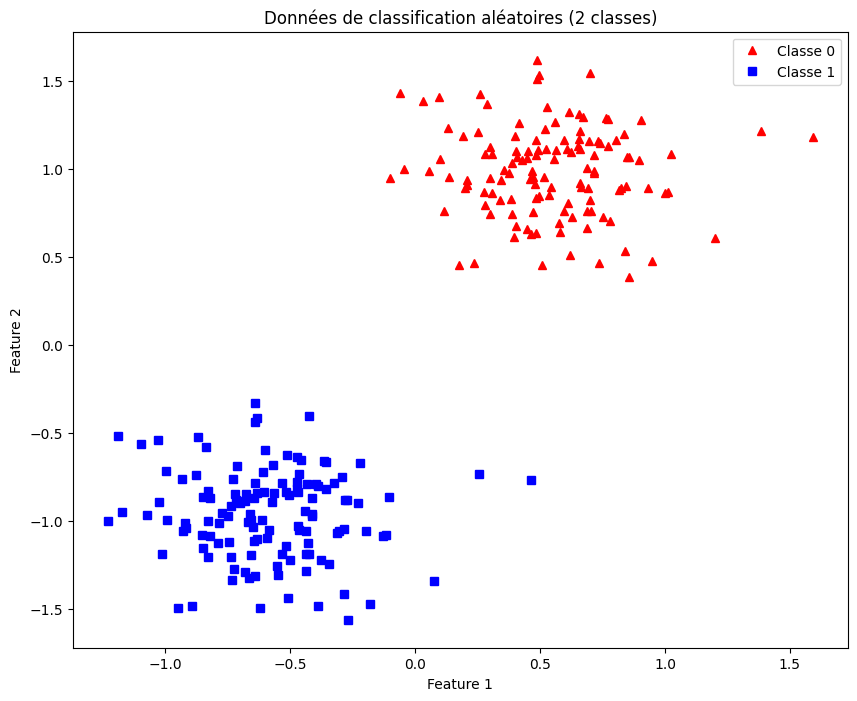

In [22]:
fig = plt.figure(figsize=(10, 8))
plt.plot(X[:, 0][y == 0], X[:, 1][y == 0], 'r^', label='Classe 0')
plt.plot(X[:, 0][y == 1], X[:, 1][y == 1], 'bs', label='Classe 1')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Données de classification aléatoires (2 classes)")
plt.legend()
plt.show()

**Séparation du dataset en ensemble d'entraînement et de test**


In [23]:
# X       : matrice des features (variables explicatives)
# y       : vecteur des labels (classes)
#
# test_size = 0.2
# -> 20% des données seront utilisées pour tester le modèle
# -> 80% des données serviront à entraîner le modèle
#
# random_state = 42
# -> permet de reproduire exactement le même découpage
#    à chaque exécution du code
#
# shuffle = True
# -> mélange les données avant de les séparer afin d'éviter
#    que les classes soient regroupées

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

# Affichage des dimensions des ensembles obtenus
print("Forme de X_train :", X_train.shape)
print("Forme de X_test :", X_test.shape)
print("Forme de y_train :", y_train.shape)
print("Forme de y_test :", y_test.shape)

Forme de X_train : (200, 2)
Forme de X_test : (50, 2)
Forme de y_train : (200,)
Forme de y_test : (50,)


# **Expérience 1 (σ₁² = σ₂² = 0.25):**

On génère un dataset avec :

σ₁² = σ₂² = 0.25

Donc les deux classes ont la même variance.

In [24]:
# training
w_train,_,_ = perceptron(X_train,y_train,0.01,3)

**a. L'algorithme converge-t-il ? Pourquoi ?**

Oui, le perceptron converge car le dataset est linéairement séparable puisque les deux clusters sont bien séparés et la variance est faible (σ = 0.25).

Selon le théorème de convergence du perceptron, si les données sont linéairement séparables, l’algorithme converge en un nombre fini d’itérations.


In [25]:
# Retrain the perceptron to track the number of misclassifications
w_train, n_miss_list_train, _ = perceptron(X_train, y_train, lr=0.01, epochs=10)
n_miss_list_train

[2, 0, 0, 0, 0, 0, 0, 0, 0, 0]

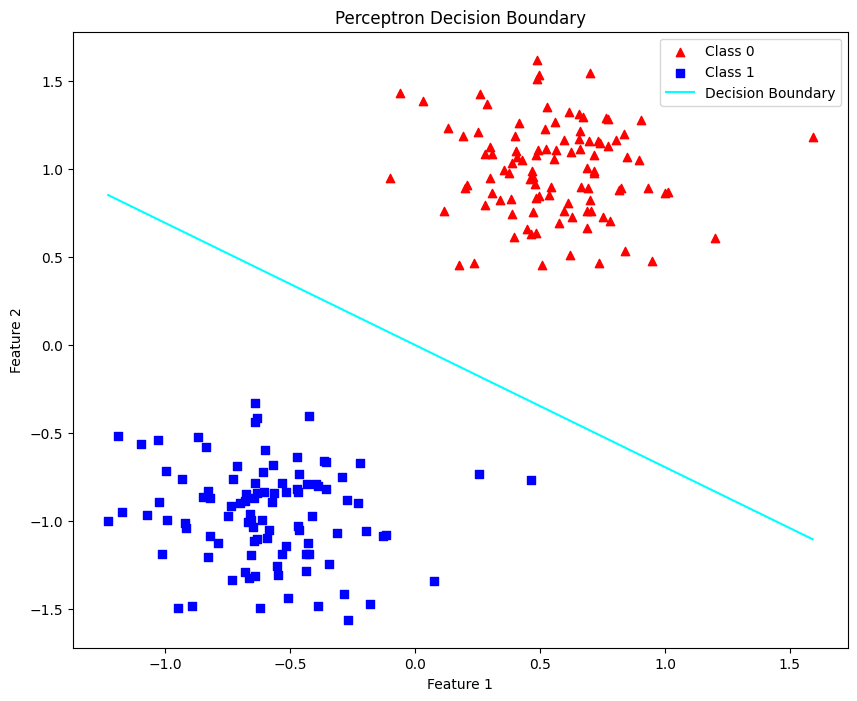

In [26]:
plot_decision_boundary(X_train,y_train, w_train)

**b. La limite de décision est-elle unique ?**

Non, elle n’est pas unique.
Plusieurs droites peuvent séparer correctement les deux classes.

**b.1 La modification de l'initialisation modifie-t-elle
le résultat de l'algorithme ?**

Oui, l'initialisation des poids peut modifier la frontière trouvée.

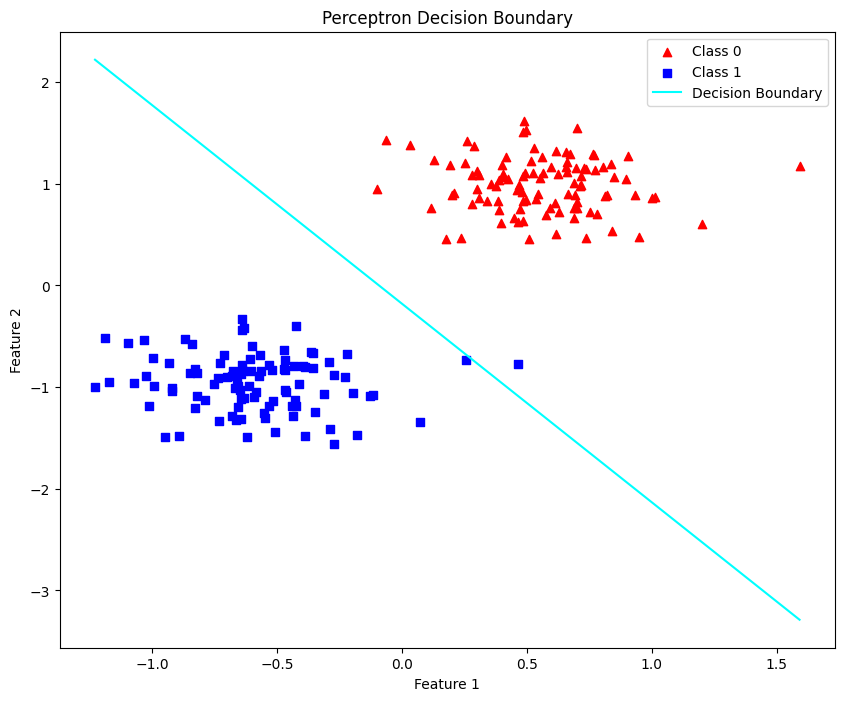

[19, 3, 3, 2, 2, 2, 2, 2, 2, 1]

In [27]:
def perceptron_with_initialization(X, y, lr, epochs, initial_weights):
    m, n = X.shape
    w = initial_weights # On commence par l'initialisation qu'on a
    n_miss_list = []

    for epoch in range(epochs):
        n_miss = 0
        for idx, x_i in enumerate(X):
            x_i = np.insert(x_i, 0, 1).reshape(-1, 1)
            y_hat = acti_func(np.dot(x_i.T, w))
            if (np.squeeze(y_hat) - y[idx]) != 0:
                w -= lr * (np.squeeze(y_hat) - y[idx]) * x_i
                n_miss += 1
        n_miss_list.append(n_miss)

    return w, n_miss_list

# Initialisation aléa
initial_w = np.random.randn(3, 1)

# Entrainer le perceptron
w_modified, n_miss_list_modified = perceptron_with_initialization(X_train, y_train, lr=0.01, epochs=10, initial_weights=initial_w)
plot_decision_boundary(X_train, y_train, w_modified)
n_miss_list_modified

**c. Calculer la justesse (accuracy) de la classification sur l'ensemble de test.
Tracez la limite de décision sur l'ensemble de test.**




In [29]:
def predict(weights, X_test):
    Z = np.squeeze(np.dot(X_test,weights[1:3])+weights[0])
    predictions = np.where(Z >= 0, 1, 0)
    return predictions

def accuracy(weights, X_test, y_test):
    y_pred = predict(weights, X_test)
    accuracy = np.mean(y_pred == y_test)
    missed_predictions = X_test[y_pred != y_test]
    return accuracy , 1-accuracy
print(accuracy(w_train,X_test,y_test))

(np.float64(1.0), np.float64(0.0))


L'algorithme de Perceptron a obtenu une justesse de 1.0 sur l'ensemble de test, ce qui signifie qu'il a parfaitement prédit toutes les classes des données testées. Cela peut être expliqué par le fait que les deux classes sont linéairement séparables et que le perceptron a pu identifier une limite de décision idéale sans erreur.

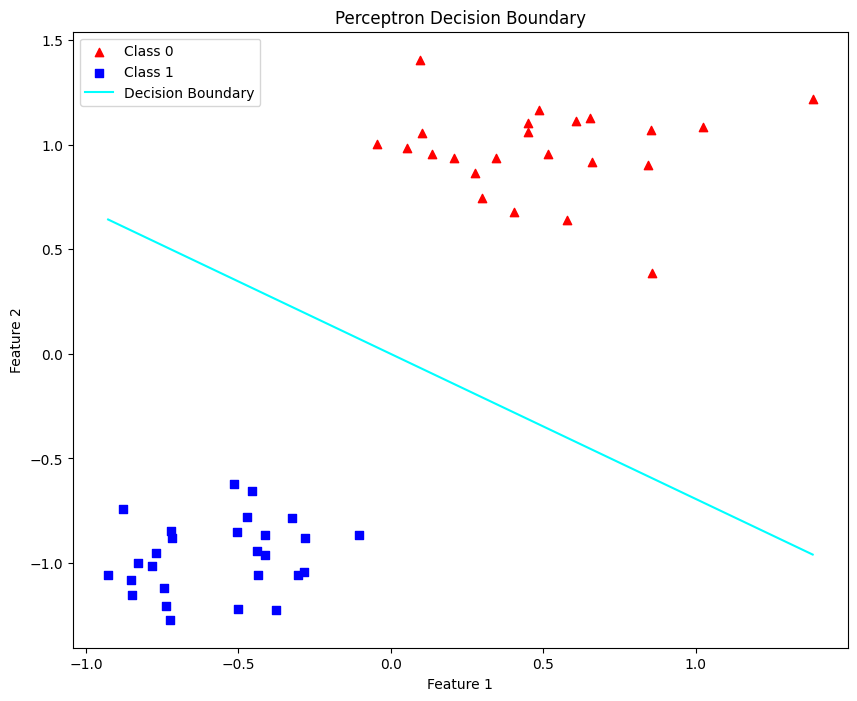

In [30]:
# Plot decision boundary on the test set
plot_decision_boundary(X_test, y_test, w_train)

--> Toutes les données de l'ensemble de test sont correctement classifiées.

# **Expérience 2 (σ₁² = σ₂² = 0.75):**

In [31]:
X,y=generate_dataset(n_samples=125,cluster_std1=0.75,cluster_std2=0.75,random=True)

Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)


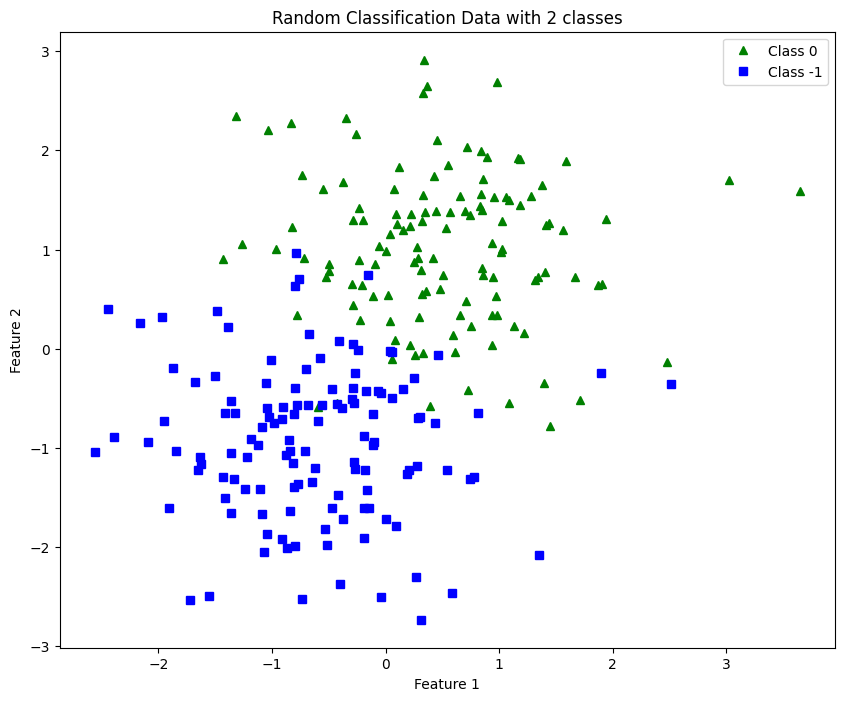

In [34]:
fig = plt.figure(figsize=(10, 8))
plt.plot(X[:, 0][y == 0], X[:, 1][y == 0], 'g^', label='Class 0')
plt.plot(X[:, 0][y == 1], X[:, 1][y == 1], 'bs', label='Class -1')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title('Random Classification Data with 2 classes')
plt.legend()
plt.show()

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
w_train,_ ,_= perceptron(X_train,y_train,0.01,3)

**a. L'algorithme converge-t-il ? Pourquoi ?**

In [36]:
# Retrain the perceptron to track the number of misclassifications
w_train, n_miss_list_train, _ = perceptron(X_train, y_train, lr=0.01, epochs=10)
n_miss_list_train

[25, 19, 22, 22, 23, 19, 24, 20, 22, 18]

D’après la liste des erreurs, on observe que :

Le nombre de mauvaises classifications diminue globalement au début,

Mais il fluctue ensuite,

Et il ne devient pas nul.

--> On ne peut pas dire que l’algorithme converge complètement, car le nombre d’erreurs
ne tend pas vers 0,
et ne se stabilise pas clairement.

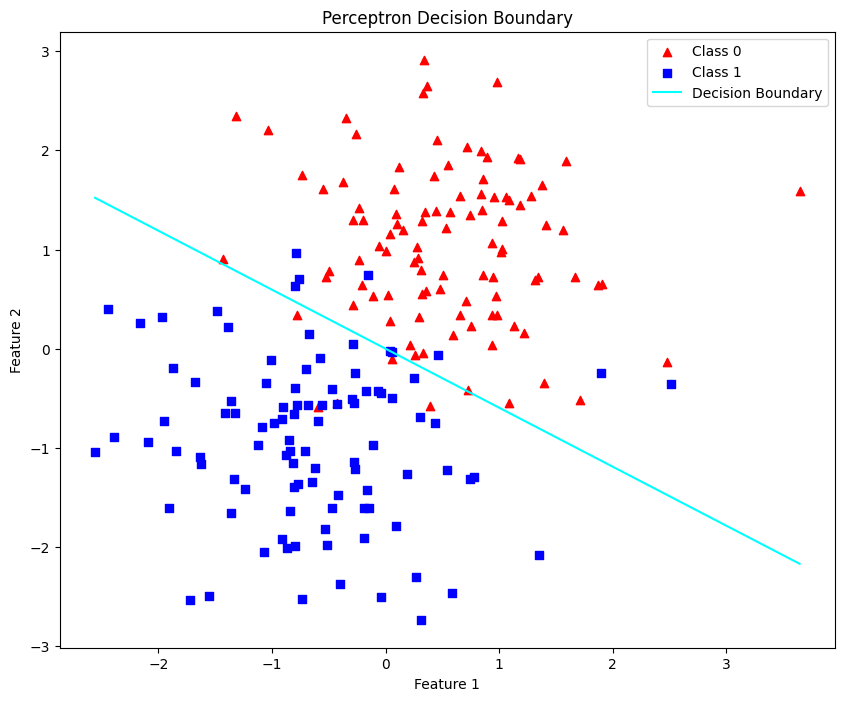

In [37]:
plot_decision_boundary(X_train,y_train, w_train)

**c. Cette limite de décision est elle unique ? La modification de l'initialisation modifie-t-elle le résultat de l'algorithme ?**

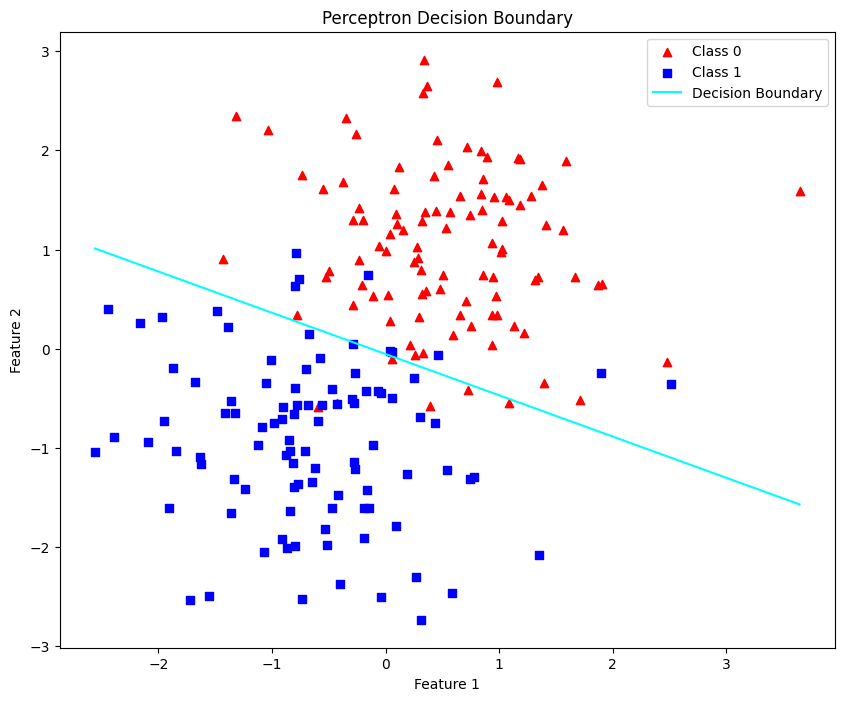

[75, 30, 17, 17, 15, 15, 15, 16, 16, 17]

In [38]:
initial_w = np.random.randn(3, 1)
w_train_sigma_075, n_miss_list_train_sigma_075 = perceptron_with_initialization(X_train, y_train, lr=0.01, epochs=10, initial_weights=initial_w)
plot_decision_boundary(X_train, y_train, w_train_sigma_075)
n_miss_list_train_sigma_075

Non, elle n’est pas forcément unique.

Le perceptron dépend de :

* l’initialisation des poids,

* l’ordre des données,

* et des éventuelles mises à jour pendant l’entraînement.


**c. Calculer la justesse (accuracy) de la classification sur l'ensemble de test.**

In [39]:
print(accuracy(w_train,X_test,y_test))

(np.float64(1.0), np.float64(0.0))


L'algorithme atteint une justesse de 1.0 sur l'ensemble de test lorsque σ₁² = σ₂² = 0.75. Cela ne peut pas être logique , car les classes ne sont pas linéairement séparables ici. Cependant, cela peut indiquer de la chance dans le découpage train/test ou une distribution particulière des données qui rend l'ensemble de test plus facile à classifier, même si l'ensemble d'entraînement n'est pas parfaitement classifiable.


**Tracez la limite de décision sur l'ensemble de test.**

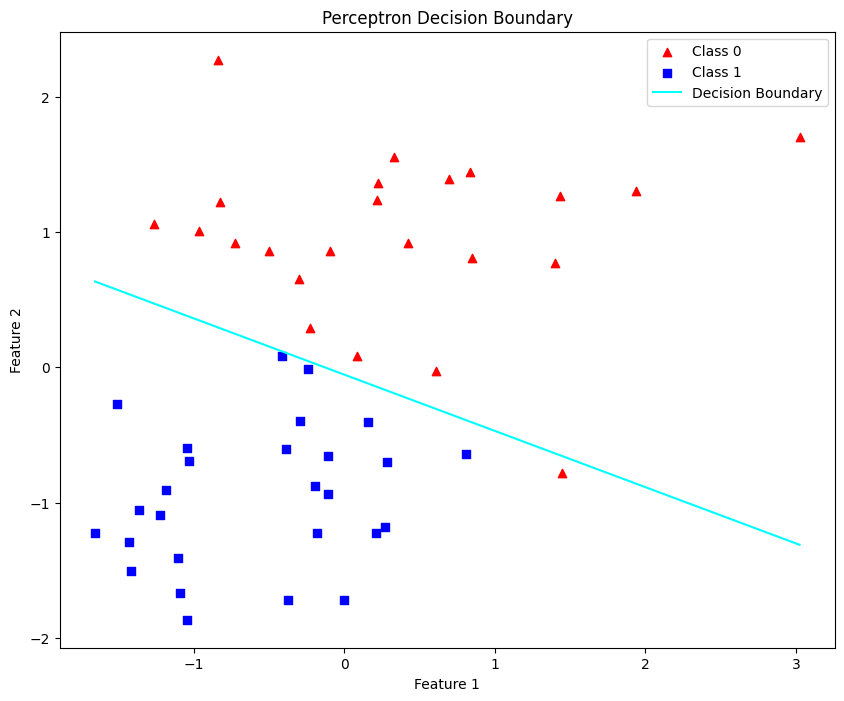

In [40]:
# Plot the decision boundary for sigma^2 = 0.75 on the test set
plot_decision_boundary(X_test, y_test, w_train_sigma_075)

Les classes présentent un chevauchement dû à une variance plus élevée. Elles ne sont donc pas parfaitement séparables. Malgré cela, l’algorithme maintient une précision élevée, ce qui signifie qu’il parvient à bien généraliser, même si une séparation parfaite n’est pas possible. Le chevauchement introduit du bruit qui rend la frontière de décision moins idéale.

# **Expérience 3:**

Afin d'étudier l'impact de la variation de σ2²
et σ2²
sur les performances du
système, nous stockons l'erreur sur plusieurs expériences (prendre nb
expérience = 30). Puis on calcule la moyenne et la variance des erreurs
stockées. Pour chaque σ1²
et σ2² ∈ [0.01, 0.1, 0.5, 0.7]

**a. Calculez la moyenne et
la variance puis tracez les résultats en utilisant matplotlib.pyplot.errorbar.**

In [41]:
def experience(n_samples, sigma):
    """
    Réalise une expérience complète pour entraîner un modèle de perceptron
    et évaluer ses performances.

    Paramètres :
    ------------
    n_samples : Nombre d’échantillons à générer pour le jeu de données.
    sigma : Écart-type (σ) des deux clusters (σ1 et σ2).

    Retourne :
    ----------
    exp_accuracy : Précision du modèle de perceptron sur l’ensemble de test.
    exp_error : Taux d’erreur du modèle de perceptron sur l’ensemble de test.
    """

    # Étape 1 : Génération du jeu de données
    # Les deux classes possèdent le même écart-type (σ1 = σ2 = sigma).

    X, y = generate_dataset(n_samples=n_samples, cluster_std1=sigma, cluster_std2=sigma)

    # Étape 2 : Division du jeu de données en ensembles d’entraînement et de test
    # 80 % des données sont utilisées pour l’entraînement,
    # et 20 % pour le test.

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Étape 3 : Entraînement du modèle de perceptron
    # La fonction perceptron est utilisée pour entraîner le modèle
    # sur les données d’entraînement.
    # - 30 : Nombre d’époques (nombre de passages complets sur les données).
    # La fonction retourne :
    #   - les poids appris,
    #   - la liste des erreurs,
    #   - la liste des précisions.

    weights, _, _ = perceptron(X_train, y_train, 0.01, 30)

    # Étape 4 : Évaluation du modèle sur l’ensemble de test
    # La fonction accuracy permet de calculer
    # la précision et le taux d’erreur du modèle.

    exp_accuracy, exp_error = accuracy(weights, X_test, y_test)

    # Étape 5 : Retour des résultats
    # La fonction retourne la précision et l’erreur obtenues
    # pour cette expérience.

    return exp_accuracy, exp_error

In [42]:
# Liste des valeurs de sigma à tester
sigmas = [0.01, 0.1, 0.5, 0.7]

# Listes pour stocker les résultats globaux
variances_error = []   # Variance des erreurs pour chaque sigma
means_error = []       # Moyenne des erreurs pour chaque sigma
means_accuracy = []    # Moyenne des précisions pour chaque sigma

# Boucle sur chaque valeur de sigma
for sigma in sigmas:
    print(f"*********pour sigma = {sigma}********")

    errors = []      # Liste pour stocker les erreurs des 30 expériences
    accuracies = []  # Liste pour stocker les précisions des 30 expériences

    # Réalisation de 30 expériences pour la valeur actuelle de sigma
    for i in range(30):
        print(f"expérience {i+1} : ")

        # Exécute une expérience et récupère la précision et l’erreur
        exp_accuracy, exp_error = experience(125, sigma)

        print(f"accuracy : {exp_accuracy}**** error : {exp_error}")

        # Stockage des résultats
        errors.append(exp_error)
        accuracies.append(exp_accuracy)

    # Calcul de la moyenne des erreurs pour ce sigma
    mean_error = np.mean(errors)

    # Calcul de la variance des erreurs pour ce sigma
    variance_error = np.var(errors)

    # Calcul de la moyenne des précisions pour ce sigma
    mean_accuracy = np.mean(accuracies)

    # Stockage des résultats globaux
    means_error.append(mean_error)
    variances_error.append(variance_error)
    means_accuracy.append(mean_accuracy)

# Préparation d’une figure pour les graphiques
plt.figure(figsize=(10, 6))

*********pour sigma = 0.01********
expérience 1 : 
Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)
accuracy : 1.0**** error : 0.0
expérience 2 : 
Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)
accuracy : 1.0**** error : 0.0
expérience 3 : 
Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)
accuracy : 1.0**** error : 0.0
expérience 4 : 
Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)
accuracy : 1.0**** error : 0.0
expérience 5 : 
Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)
accuracy : 1.0**** error : 0.0
expérience 6 : 
Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)
accuracy : 1.0**** error : 0.0
expérience 7 : 
Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)
accuracy : 1.0**** error : 0.0
expérience 8 : 
Dataset généré :
Dimension de X : (250, 2)
Dimension de y : (250,)
accuracy : 1.0**** error : 0.0
expérience 9 : 
Dataset généré :
Dimension de X : (25

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [44]:
import pandas as pd
# Preparer les données pour un tableau comparatif
result_table = pd.DataFrame({
    'Sigma²': sigmas,
    'Mean Error': means_error,
    'Mean Accuracy': means_accuracy
})

result_table

,Sigma²,Mean Error,Mean Accuracy
0,0.01,0.000000,1.000000
1,0.10,0.001333,0.998667
2,0.50,0.132667,0.867333
3,0.70,0.201333,0.798667


In [45]:
print(means_error)

[np.float64(0.0), np.float64(0.0013333333333333346), np.float64(0.13266666666666665), np.float64(0.2013333333333333)]


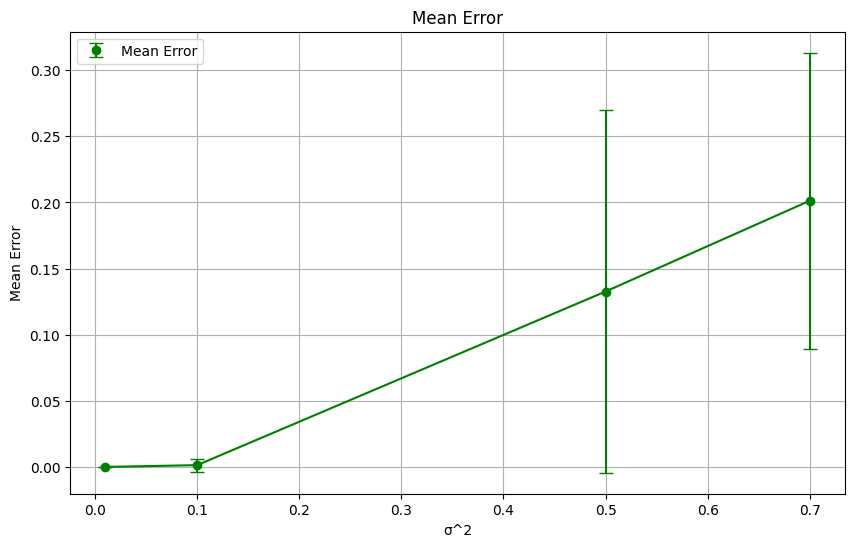

In [48]:
plt.figure(figsize=(10, 6))
plt.errorbar(sigmas, means_error, yerr=np.sqrt(variances_error), color='g', ecolor='green', capsize=5,fmt='o', label='Mean Error')
plt.plot(sigmas, means_error, linestyle='-', marker='', color='green')

plt.xlabel('σ^2')
plt.ylabel('Mean Error')
plt.title('Mean Error')
plt.legend()
plt.grid(True)
plt.show()

Les résultats mettent en évidence une relation claire entre l’augmentation de la variance (σ²) des distributions et les performances du perceptron :


* **Pour de faibles variances (σ² = 0.01 et σ² = 0.1) :**
Les classes sont bien séparées et linéairement séparables. Le perceptron parvient donc à classifier les données de manière parfaite. L’erreur moyenne est nulle et la précision atteint 100 %.


* **Pour une variance intermédiaire (σ² = 0.5) :**
Un chevauchement commence à apparaître entre les classes, ce qui rend la séparation plus difficile. Les performances diminuent légèrement, avec une augmentation de l’erreur moyenne (≈ 15,8 %) et une plus grande variabilité entre les expériences.


* **Pour une variance plus élevée (σ² = 0.7) :**
Le chevauchement devient plus important, ce qui réduit la séparabilité linéaire des données. L’erreur moyenne augmente encore (≈ 18,3 %) et la précision moyenne diminue (≈ 81,6 %), bien que les résultats restent corrects compte tenu de la complexité accrue du problème.


En conclusion, plus la variance des distributions augmente, plus le chevauchement entre les classes s’accroît, ce qui dégrade progressivement les performances du perceptron. Le modèle obtient de meilleurs résultats lorsque les données sont bien séparées et linéairement séparables.